# How to use the heavy ion hard probes format (**HIONHPOD**)

The heavy ion hard probes release of ***ATLAS*** *Open Data* consists of data collected/produced by ATLAS in the hard probes stream during lead-lead collisions in Run 2 of the LHC. These data have been released in a format designed explicitly for heavy ion hard probes analyses: the **HIONHPOD** format. This notebook will demonstrate accessing these data and loading their events and analysis variables in `uproot`.

First, we will need to install `atlasopenmagic`, which is our interface for accessing these data in Python:

In [1]:
# Install atlasopenmagic
%pip install atlasopenmagic
# Install required packages (uproot, awkward, etc.) to environment
import atlasopenmagic as atom
from atlasopenmagic import install_from_environment
install_from_environment()

Note: you may need to restart the kernel to use updated packages.
Installing packages: ['aiohttp>=3.9.5', 'atlasopenmagic>=1.9.0', 'awkward>=2.6.7', 'awkward-pandas>=2023.8.0', 'coffea~=0.7.0', 'fsspec>=2025.7.0', 'hist>=2.8.0', 'ipykernel>=6.29.5', 'jupyter>=1.0.0', 'lmfit>=1.3.2', 'matplotlib>=3.9.1', 'metakernel>=0.30.2', 'notebook<7', 'numpy>=1.26.4', 'pandas>=2.2.2', 'papermill>=2.6.0', 'pip>=24.2', 'scikit-learn>=1.5.1', 'uproot>=5.3.10', 'uproot3>=3.14.4', 'fsspec-xrootd>=0.5.1', 'jupyterlab_latex~=3.1.0', 'vector>=1.4.1']
  Using cached coffea-0.7.31-py2.py3-none-any.whl.metadata (9.6 kB)
  Using cached ipykernel-7.4.0-py3-none-any.whl.metadata (3.4 kB)
  Using cached coffea-0.7.30-py2.py3-none-any.whl.metadata (9.6 kB)
INFO: pip is looking at multiple versions of coffea to determine which version is compatible with other requirements. This could take a while.
  Using cached coffea-0.7.29-py2.py3-none-any.whl.metadata (9.6 kB)
  Using cached coffea-0.7.28-py2.py3-none-any.whl.m

The `install_from_enivronment` method has handily installed a number of helpful modules which we can use to handle these data, so we can now import them here.

In [2]:
# In case any of these imports fails, please restart the jupyter kernel and try again - it is likely the environment just needs to be updated
import uproot   # handle ROOT files
import awkward as ak    # nested, variable sized data arrays
import vector   # Lorentz vectors
import numpy as np
vector.register_awkward()
import matplotlib.pyplot as plt # plotting

## Finding data

By default, the `atlasopenmagic` package is set to use the proton-proton data for research (`2024r-pp`) dataset. We would like the heavy ion hard probes release, so we call `atom.set_release()` and switch over to `2026r-hihp`.

In [3]:
atom.set_release("2026r-hihp")

Fetching metadata for release: 2026r-hihp...
Fetching datasets: 100%|██████████| 57/57 [00:00<00:00, 605.51datasets/s]
✓ Successfully cached 57 datasets.
Active release: 2026r-hihp. (Datasets path: REMOTE)


We check available dataset IDs (DSIDs) in the release by calling `atom.available_datasets()`.

In [4]:
dsids = atom.available_datasets()
print(f'There are {len(dsids)} DSIDs available in 2026r-hihp. For example:\n'\
      f'{dsids[:3]+dsids[-3:]}')

There are 57 DSIDs available in 2026r-hihp. For example:
['300000', '420010', '420011', '700911', '700912', 'data']


If we want to find some $t\bar{t}$ MC samples, we can search for these in the MC metadata. Each MC sample has an associated physics description, so if we filter for `ttbar`, we find:

In [5]:
atom.match_metadata('description', 'ttbar')

[('601235', 'PhPy8EG_A14_ttbar_hdamp258p75_dil_pp'),
 ('601236', 'PhPy8EG_A14_ttbar_hdamp258p75_dil_pn'),
 ('601475', 'PhPy8EG_A14_ttbar_hdamp258p75_dil_nn'),
 ('601476', 'PhPy8EG_A14_ttbar_hdamp258p75_dil_np')]

There are four dileptonic $t\bar{t}$ samples in the release, each generated with different colliding nucleons. Let's look in more detail at the neutron-neutron dataset.

We can retrieve this dataset by getting all the urls corresponding to its DSID, `601475`. There are two choices of streaming protocol, **xrootd** (`protocol=root`) or **https** (`protocol=https`). Streaming should be faster with xrootd, so we will stick with this in this demonstration. 

In [6]:
urls_sample = atom.get_urls(601475,protocol="root",cache=False)
urls_sample[:3]

['root://eospublic.cern.ch:1094//eos/opendata/atlas/rucio/mc15_5TeV/DAOD_HIONHPOD.51678177._000001.pool.root.1',
 'root://eospublic.cern.ch:1094//eos/opendata/atlas/rucio/mc15_5TeV/DAOD_HIONHPOD.51678177._000002.pool.root.1',
 'root://eospublic.cern.ch:1094//eos/opendata/atlas/rucio/mc15_5TeV/DAOD_HIONHPOD.51678177._000003.pool.root.1']

Otherwise, we can also access collision data by simpling switching the the `data` dsid. Let's try and manipulate the first `data` url we can find.

In [7]:
filename = atom.get_urls('data', protocol='root', cache=False)[0]
filename

'root://eospublic.cern.ch:1094//eos/opendata/atlas/rucio/data15_hi/DAOD_HIONHPOD.51678081._000001.pool.root.1'

## Reading the **HIONHPOD** format with uproot

We have now retrieved the path to one `TFile` stored on `eos/`. We can open this file using `uproot.open`, revealing the `TTree` objects inside, which we can check with the `.keys()` method.

In [8]:
print("TTree objects inside the ROOT file:")
for key in uproot.open(filename).keys():
    print("-",key)

TTree objects inside the ROOT file:
- ##Params;3
- ##Params;2
- ##Shapes;3
- ##Shapes;2
- ##Links;3
- ##Links;2
- MetaData;1
- MetaDataHdr;1
- MetaDataHdrForm;1
- CollectionTree;1
- POOLContainer;1
- POOLContainerForm;1
- POOLCollectionTree;1


All of our variables for analysis are stored in the `CollectionTree`, which we are able to open directly by passing a `{filename: treename}` dictionary. 

In [9]:
tree = uproot.open({filename: "CollectionTree"})

### Listing branches
Data in the HIONHPOD format are stored in branches of the `CollectionTree`, and are typically of type `vector<int>` or `vector<float>` (a vector of integers or a vector of floats). We can see all branches in the tree with the `.show()` method; here we show the first 10 branches. We can also pass a few extra arguments to this method for a more aesthetic readout...

In [10]:
first_ten_branches = list(tree.keys())[:10]
tree.show(filter_name=first_ten_branches, name_width=50, typename_width=50, interpretation_width=50)

name                                               | typename                                           | interpretation                                    
---------------------------------------------------+----------------------------------------------------+---------------------------------------------------
TrigConfKeys                                       | xAOD::TrigConfKeys_v1                              | AsStridedObjects(Model_xAOD_3a3a_TrigConfKeys_5...
xTrigDecisionAux.                                  | xAOD::TrigDecisionAuxInfo_v1                       | AsObjects(Model_xAOD_3a3a_TrigDecisionAuxInfo_5...
EventInfo                                          | xAOD::EventInfo_v1                                 | AsStridedObjects(Model_xAOD_3a3a_EventInfo_5f_v...
xTrigDecision                                      | xAOD::TrigDecision_v1                              | AsStridedObjects(Model_xAOD_3a3a_TrigDecision_5...
EventInfoAux.                                      | xAOD:

### Loading branches into `awkward` / `numpy` arrays
We can get the branch of a TTree by indexing it with `['branch_name']` and calling `.array()` to read it as an array.

In [11]:
mu_pt = tree["MuonsAuxDyn.pt"].array()

Branches are loaded in `uproot` with `awkward` arrays. Here, we got the transverse momentum ($p_\mathrm{T}$) of all muons in every event stored in the file. We have a variable number of muons in each event (e.g. some elements of this array may even be empty where no muons are reconstructed in the event), across a total of 13,000 events.

In [12]:
mu_pt

<Array [[3.61e+03], [...], ..., [2.48e+03, ...]] type='14864 * var * float32'>

> Note: `13000 * var * float32` implies: 14,000 events, each corresponding to an array of variable length (including empty/zero length), and containing floats (the $p_\mathrm{T}$ of the muons in a given event).

We can flatten this array into a one-dimensional array and plot its distribution:

In [13]:
mu_pt_np = ak.flatten(mu_pt).to_numpy()
print(f"Total number of muons in 13,000 events: {len(mu_pt_np):,}")
mu_pt_np

Total number of muons in 13,000 events: 51,485


array([3613.2793, 2227.186 , 3400.9407, ..., 2521.903 , 2207.7974,
       1315.0101], shape=(51485,), dtype=float32)

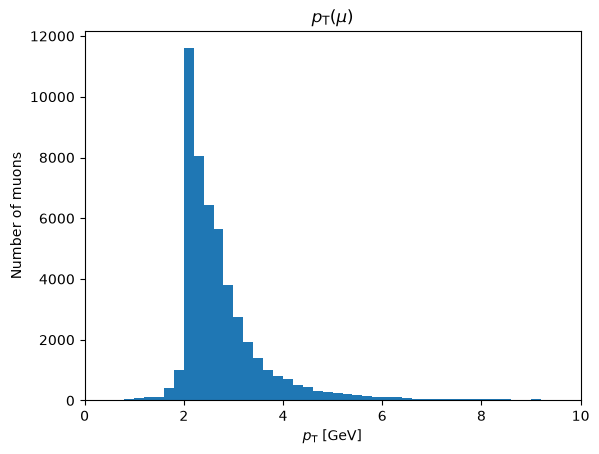

In [14]:
pT_range = (0,10)
plt.hist(mu_pt_np*1e-3,range=pT_range,bins=50) # Convert pT to GeV (default MeV), plot around maximum peak
plt.xlim(pT_range)
plt.title(r"$p_\mathrm{T}(\mu)$")
plt.xlabel(r"$p_\mathrm{T}$ [GeV]")
plt.ylabel("Number of muons")
plt.show()

Let's also look at the centralities of our collision events. In ATLAS, the centrality of an event is determined via forward calorimeter (FCal) measurements and is stored as a range in the `CentralityMin` and `CentralityMax` variables.

In [15]:
# Load centrality ranges and event numbers
centrality_min = tree["EventInfoAuxDyn.CentralityMin"].array()
centrality_max = tree["EventInfoAuxDyn.CentralityMax"].array()
eventNumber = tree["EventInfoAuxDyn.eventNumber"].array()

print(f'Event {eventNumber[0]} is in the centrality range ({centrality_min[0]} - {centrality_max[0]}) %')

Event 313082 is in the centrality range (22.0 - 23.0) %


We can use these branches, in combination with the `eventNumber` branch, to bin our events by centrality.

In [16]:
# Define centrality bins
centrality_ranges = {
    "(60 - 100)%": {
        "lims": (60., 100.),
    },
    "(40 - 60)%": {
        "lims": (40., 60.),
    },
    "(20 - 40)%": {
        "lims": (20., 40.),
    },
    "(0 - 20)%": {
        "lims": (0., 20.),
    },
}
# # Cut out events with poorly defined centrality (min == 80, max == 0.1)
# undefined_mask = (centrality_min == 80) & (centrality_max == 0.1)
# Run through centrality limits and mask eventNumbers to organise them into centrality bins
for cr in centrality_ranges:
    lower, upper = centrality_ranges[cr]["lims"]
    centrality_mask = (centrality_max < upper) & (centrality_min > lower)# & ~undefined_mask
    centrality_ranges[cr]["eventNumber"] = eventNumber[centrality_mask]

For example, we can look at the highly central event numbers:

In [17]:
print(centrality_ranges["(0 - 20)%"]["eventNumber"])

[313287, 298418, 299830, 388508, ..., 1679284, 1341853, 1676132, 1573628]


and produce an overall centrality distribution of our events:

Text(0.5, 0, 'Centrality range')

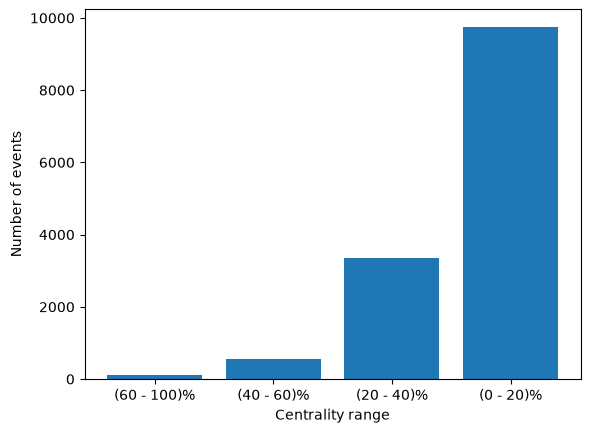

In [18]:
plt.bar(
    [cr for cr in centrality_ranges],
    [len(centrality_ranges[cr]["eventNumber"]) for cr in centrality_ranges]
)
plt.ylabel("Number of events")
plt.xlabel("Centrality range")

We can then match this event number binning to our muon event numbers in order to bin our muons by centrality. For this, we load our muon branches alongside event numbers, so that we can easily match muon events to event numbers.

In [19]:
muons = ak.zip({
    'pT': tree["MuonsAuxDyn.pt"].array(),
    'eventNumber': tree['EventInfoAuxDyn.eventNumber'].array()
})
print(f'Muons: {muons}')
print(f'Muon pT: {muons.pT}')
print(f'Muon event numbers: {muons.eventNumber}')

Muons: [[{pT: 3.61e+03, eventNumber: 313082}], ..., [{pT: 2.48e+03, ...}, ..., {...}]]
Muon pT: [[3.61e+03], ..., [2.48e+03, 1.61e+03, 2.73e+03, ..., 2.21e+03, 1.32e+03]]
Muon event numbers: [[313082], ..., [1573628, 1573628, 1573628, ..., 1573628, 1573628, 1573628]]


The `ak.zip` method automatically broadcasts our arrays such that each branch in the output array has the same nested structure. For example, you can see above that, where the muon $p_\mathrm{T}$ is empty, no event number is stored, and, where multiple muons are recored, multiple event numbers are stored. This will cause problems for us when we try to match event numbers to our centrality definitions. To account for the first problem, we can remove all of the events where no muons are recorded by applying a selection.

In [20]:
print(f'Minimum number of muons before cut: {min(ak.num(muons))}')
print(f'First few event numbers: {muons.eventNumber[:3]}')
cut_muons = muons[ak.where(ak.num(muons) >= 1)]
print(f'\nMinimum number of muons after cut: {min(ak.num(cut_muons))}')
print(f'First few event numbers: {cut_muons.eventNumber[:3]}')

Minimum number of muons before cut: 0
First few event numbers: [[313082], [313287, 313287, 313287], [298418, 298418, 298418]]

Minimum number of muons after cut: 1
First few event numbers: [[313082], [313287, 313287, 313287], [298418, 298418, 298418]]


Then, we loop through our centrality dictionary and check if muon event numbers are in each centrality range. If they are, we store the muons corresponding to those event numbers in the dictionary at the centrality range. In order to match the dimensions of the event number array stored in our dictionaries, we only take the first event number stored in each muon event.

In [21]:
for cr in centrality_ranges:
    centrality_ranges[cr]['muons'] = cut_muons[np.isin(cut_muons['eventNumber'][:,0], centrality_ranges[cr]["eventNumber"])]
    print(f'Muons in {cr}: {len(centrality_ranges[cr]["muons"])}')

Muons in (60 - 100)%: 49
Muons in (40 - 60)%: 289
Muons in (20 - 40)%: 2649
Muons in (0 - 20)%: 9541


> **Note:** We have for more highly central muons in this hard probes dataset! This is expected: low centrality collisions are dominated by soft scattering process. These produce soft muons which are not expected to pass hard probes triggers.

Finally, we can plot the $p_\mathrm{T}$ distribution of our muons in bins of centrality!

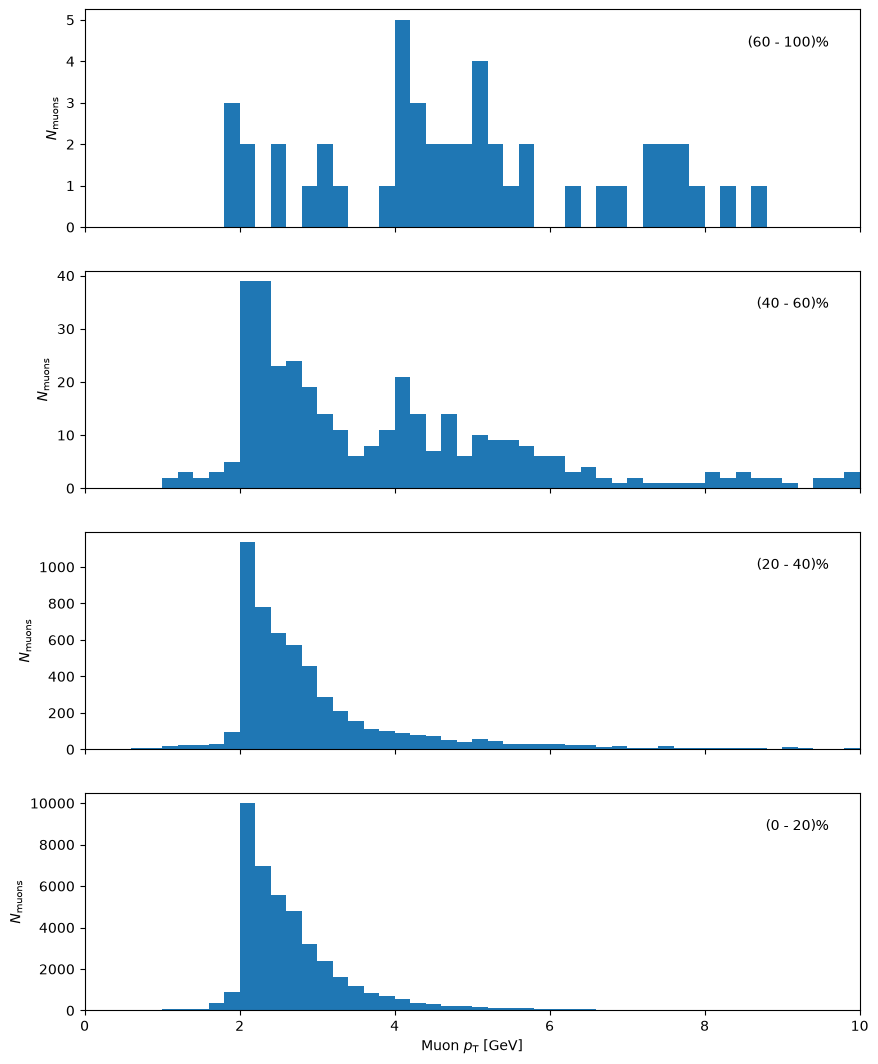

In [22]:
# Create a figure with 4 subplots
fig, axs = plt.subplots(4, 1, sharex=True, figsize=(10,13))

# Loop through centrality ranges, flatten muon pT distributions and plot
for i, cr in enumerate(centrality_ranges):
    flat_pt = ak.to_numpy(ak.flatten(centrality_ranges[cr]['muons']['pT']))

    # Plot distribution
    axs[i].hist(flat_pt*1e-3, range=pT_range, bins=50)
    # Stamp axes with centrality range
    axs[i].text(.96, .88, cr, transform=axs[i].transAxes, ha="right", va="top")

    axs[i].set_ylabel(r'$N_\mathrm{muons}$')

axs[-1].set_xlim(pT_range)
_ = axs[-1].set_xlabel(r'Muon $p_\mathrm{T}$ [GeV]')

You may already spot that there are signs of a centrality-depedent suppression of muon $p_\mathrm{T}$. Why could this be?

Now you can pursure your own analyses with these data! If you'd like to check out an example hard probes analysis, there is also a more detailed [analysis notebook](https://opendata.atlas.cern/) exploring centrality-dependent dijet suppression.

## Producing analysis NTuples from **HIONHPOD**
Whilst the **HIONHPOD** format has been designed to be as light-weight as possible, the files are still large and run-time can be throttled by network downlad speeds. In some cases, an effective solution may be to produce local, smaller-scale NTuples for use in your analysis. We would recommend using a C++ NTuple framework for this. For example, you may follow the instructions in [Writing NTuples and Trees using the Text Configuration](https://atlas-software.docs.cern.ch/analysis/analysis_tutorial/AnalysisSWTutorial/cpalg_ntuple/) from the [ATLAS Analysis Software Tutorial](https://atlas-software.docs.cern.ch/analysis/).